# XGBoost for classification

[Master Tree Ensemble Models course](https://www.trainindata.com/p/master-tree-ensemble-models)

In this notebook, we train XGBoost to predict which clients subscribe to a term deposit. We train with early stopping, then compare the approximate and the histogram split finding algorithms, the missing values left as they are against the missing values filled, and look at how the regularization parameters `gamma` and `lambda` change the trees. Then, we train with callbacks that print the score, change the learning rate and save checkpoints, save and load the model, and resume the training from a checkpoint. Finally, we compare the three types of feature importance.

XGBoost ships a scikit-learn wrapper, `XGBClassifier` and `XGBRegressor`, which fits into scikit-learn pipelines and searches. In this course we use the native API, `xgb.train` with a `DMatrix`, because it exposes the full feature set of the library.

In [1]:
import pathlib
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

### Load data

We use the bank marketing data that we prepared in the notebook of the folder prepare-data.

In [2]:
df = pd.read_csv("../prepare-data/bank_marketing.csv")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,NaN,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,NaN,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,NaN,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,NaN,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,NaN,0,unknown,0


In [3]:
# XGBoost splits on categories directly, so we keep them as pandas categories instead of integers
categorical_vars = df.select_dtypes("str").columns
df[categorical_vars] = df[categorical_vars].astype("category")

# XGBoost takes missing values, so we leave NaN as it is

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,NaN,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,NaN,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,NaN,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,NaN,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,NaN,0,unknown,0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="y"),
    df["y"],
    test_size=0.3,
    stratify=df["y"],
    random_state=0,
)

X_train.shape, X_test.shape

((31647, 16), (13564, 16))

In [5]:
# the fraction of clients that subscribe to the term deposit
y_train.mean(), y_test.mean()

(np.float64(0.11697791259835055), np.float64(0.1170008846947803))

### Build the data containers

The native API takes its data in a `DMatrix`. We build each one once and reuse it in every model of the notebook.

In [6]:
dtrain = xgb.DMatrix(X_train, label=y_train, enable_categorical=True)
dtest = xgb.DMatrix(X_test, label=y_test, enable_categorical=True)

dtrain.num_row(), dtest.num_row()

(31647, 13564)

### Train the model with the default parameters

We show the hyperparameters with their default values, so that we can see the effect of changing them later on.

In [7]:
params = {
    # learning task
    "objective": "binary:logistic",
    "eval_metric": "auc",          # the default for this objective is logloss

    # tree structure and algorithm
    "booster": "gbtree",
    "tree_method": "hist",
    "eta": 0.3,                    # the learning rate
    "grow_policy": "depthwise",
    "max_bin": 256,
    "max_depth": 6,
    "max_leaves": 0,               # 0 means no limit
    "min_child_weight": 1,

    # regularization
    "gamma": 0,
    "lambda": 1,
    "alpha": 0,

    # sampling
    "subsample": 1,
    "sampling_method": "uniform",
    "colsample_bytree": 1,
    "colsample_bylevel": 1,
    "colsample_bynode": 1,

    # categorical features
    "max_cat_to_onehot": 4,
    "max_cat_threshold": 64,

    # hardware and reproducibility
    "device": "cpu",
    "nthread": 4,                  # fixed, so that the timings are comparable
    "seed": 0,
}

We let XGBoost add up to 2000 trees and stop when the roc-auc in the test set has not improved for 50 rounds. Here, to keep the notebook short, the test set plays the role of the validation set. In a real project, we would hold out a separate validation set, because choosing the number of trees on the test set makes the test score optimistic.

In [8]:
evals_result = {}

booster = xgb.train(
    params,
    dtrain,
    num_boost_round=2000,
    evals=[(dtrain, "train"), (dtest, "test")],
    early_stopping_rounds=50,
    evals_result=evals_result,
    verbose_eval=50,
)

[0]	train-auc:0.87871	test-auc:0.86671


[50]	train-auc:0.97573	test-auc:0.93376


[85]	train-auc:0.98543	test-auc:0.93248


In [9]:
# best_iteration counts from 0, so the best model has one tree more
num_rounds = booster.best_iteration + 1

print(f"best number of trees: {num_rounds}, trees in the booster: {booster.num_boosted_rounds()}")

best number of trees: 36, trees in the booster: 86


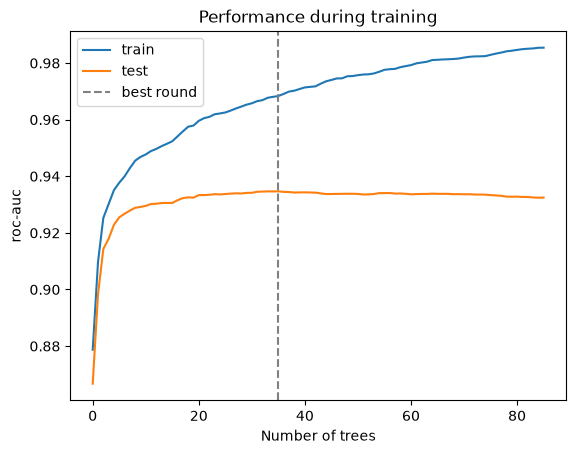

In [10]:
plt.plot(evals_result["train"]["auc"], label="train")
plt.plot(evals_result["test"]["auc"], label="test")
plt.axvline(booster.best_iteration, color="grey", linestyle="dashed", label="best round")
plt.xlabel("Number of trees")
plt.ylabel("roc-auc")
plt.title("Performance during training")
plt.legend()
plt.show()

The test roc-auc peaked with 36 trees, but the booster holds 86, because early stopping waited 50 more rounds. XGBoost keeps those extra trees, and `predict` uses all of them by default, while its scikit-learn wrapper predicts with the best round, and LightGBM and CatBoost return a model cut to the best round. So here we cut the booster ourselves.

In [11]:
# keep only the trees up to the best round
booster = booster[:booster.best_iteration + 1]

booster.num_boosted_rounds()

36

In [12]:
def evaluate(model, dtrain, y_train, dtest, y_test):
    for name, data, y in [("train", dtrain, y_train), ("test", dtest, y_test)]:
        probabilities = model.predict(data)
        balanced_accuracy = balanced_accuracy_score(y, probabilities > 0.5)
        roc_auc = roc_auc_score(y, probabilities)
        print(f"{name} balanced accuracy: {balanced_accuracy:.4f}, roc-auc: {roc_auc:.4f}")

evaluate(booster, dtrain, y_train, dtest, y_test)

train balanced accuracy: 0.8191, roc-auc: 0.9684
test balanced accuracy: 0.7387, roc-auc: 0.9347


The test roc-auc of 0.935 is higher than the 0.921 of the gradient boosting machine with the default parameters in the previous section. The roc-auc tells us how well the model ranks the clients, independently of the threshold, so we use it to compare the models in the rest of the notebook.

Let's now change one hyperparameter at a time to understand what is going on.

In [13]:
def timed_train(params, dtrain, num_boost_round):
    start = time.perf_counter()
    model = xgb.train(params, dtrain, num_boost_round)
    return model, time.perf_counter() - start

In [14]:
def test_scores(model, dtest, y_test):
    probabilities = model.predict(dtest)
    return {
        "balanced accuracy": balanced_accuracy_score(y_test, probabilities > 0.5),
        "roc-auc": roc_auc_score(y_test, probabilities),
    }

### Split finding algorithms

We saw in the lectures on split finding and the weighted quantile sketch that the approximate algorithm computes the gain only at a few candidate thresholds, placed at quantiles of the feature weighted by the Hessians and proposed again before each tree. At the end of the lecture on the weighted quantile sketch, we also mentioned the histogram method, today's default, which picks its candidates only once, before training, and does not weight them. We compare the two.

We train both for the number of trees that early stopping found, so that differences in time come from the method and not from the number of trees. The times depend on the machine, so we should read them relative to each other.

In [15]:
results = {}
for tree_method in ["approx", "hist"]:
    model, seconds = timed_train({**params, "tree_method": tree_method}, dtrain, num_rounds)
    results[tree_method] = {**test_scores(model, dtest, y_test), "seconds": seconds}

pd.DataFrame(results).T.round(4)

,balanced accuracy,roc-auc,seconds
approx,0.7361,0.9340,0.3597
hist,0.7387,0.9347,0.1297


Both methods reach almost the same roc-auc, 0.934 and 0.935. The histogram method is faster.

### Missing values

We saw in the lecture on sparsity-aware split finding that every split learns a default direction for the missing values. In that lecture, we also mentioned a simple alternative, filling them with a value outside the distribution, which puts all of them on one side of every split.

To compare the two, we fill every missing value with -1 and train on it next to the data where the missing values are left to XGBoost. In the bank marketing data, only `pdays` has missing values, for the 82% of clients who were not contacted in a previous campaign.

In [16]:
# we replace NaN by a value outside the distribution, before the categories are set
df_filled = pd.read_csv("../prepare-data/bank_marketing.csv").fillna(-1)
df_filled[categorical_vars] = df_filled[categorical_vars].astype(str).astype("category")

In [17]:
# the same split as before, so the filled data has the same rows in train and test
X_train_filled, X_test_filled, _, _ = train_test_split(
    df_filled.drop(columns="y"),
    df_filled["y"],
    test_size=0.3,
    stratify=df_filled["y"],
    random_state=0,
)

In [18]:
dtrain_filled = xgb.DMatrix(X_train_filled, label=y_train, enable_categorical=True)
dtest_filled = xgb.DMatrix(X_test_filled, label=y_test, enable_categorical=True)

In [19]:
settings = {
    "nothing filled": (dtrain, dtest),
    "everything filled with -1": (dtrain_filled, dtest_filled),
}

results = {}
for name, (train_data, test_data) in settings.items():
    model = xgb.train(params, train_data, num_rounds)
    results[name] = test_scores(model, test_data, y_test)

pd.DataFrame(results).T.round(4)

,balanced accuracy,roc-auc
nothing filled,0.7387,0.9347
everything filled with -1,0.7327,0.9333


The two models perform almost the same, with a test roc-auc of 0.935 without filling and 0.933 with -1, so the fact that a client was not contacted reaches the trees either way, and the built-in handling saves us from choosing a fill value.

### Regularization with gamma and lambda

In the lecture on the regularized objective, we added two penalties to every tree. The parameter `gamma` is subtracted from the gain of every split, so a split is only made when its gain is larger than `gamma`. The parameter `lambda` is added to the Hessian sum in the leaf values and in the gain, so it shrinks the leaf values.

With the log loss, the Hessian of a client is at most 0.25, so most splits have small gains, and values of `gamma` between 1 and 100 already make a difference.

Next to the roc-auc, we record the mean number of leaves per tree for `gamma` and the mean absolute leaf weight for `lambda`.

In [20]:
def mean_leaves(model):
    trees = model.trees_to_dataframe()
    return trees[trees["Feature"] == "Leaf"].groupby("Tree").size().mean()


def mean_abs_weight(model):
    # in the rows of the leaves, the column Gain holds the leaf weight
    trees = model.trees_to_dataframe()
    return trees.loc[trees["Feature"] == "Leaf", "Gain"].abs().mean()

In [21]:
def sweep(param, values, column, summary):
    results = {}
    for value in values:
        model = xgb.train({**params, param: value}, dtrain, num_rounds)
        results[value] = {
            "train roc-auc": roc_auc_score(y_train, model.predict(dtrain)),
            "test roc-auc": roc_auc_score(y_test, model.predict(dtest)),
            column: summary(model),
        }
    return pd.DataFrame(results).T

In [22]:
def plot_sweep(results, param, column):
    # the values are far apart, so we place them at equal distances
    positions = range(len(results))
    left = plt.gca()
    plt.plot(positions, results["train roc-auc"], marker="o", label="train roc-auc")
    plt.plot(positions, results["test roc-auc"], marker="o", label="test roc-auc")
    plt.xticks(positions, results.index)
    plt.xlabel(param)
    plt.ylabel("roc-auc")
    right = plt.twinx()
    plt.plot(positions, results[column], marker="o", color="grey", linestyle="dashed", label=column)
    # the leaves and the weights start at 0, so that small changes do not look large
    plt.ylim(0, 1.1 * results[column].max())
    plt.ylabel(column)
    # one legend for the lines of both axes, below the plot so that it hides no point
    plt.legend(handles=left.get_lines() + right.get_lines(), loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=3)
    plt.title(f"Effect of {param}")
    plt.show()

In [23]:
gamma_results = sweep("gamma", [0, 1, 10, 50, 100], "leaves per tree", mean_leaves)

gamma_results.round(4)

,train roc-auc,test roc-auc,leaves per tree
0,0.9684,0.9347,45.6111
1,0.9680,0.9331,41.7778
10,0.9411,0.9292,8.2500
50,0.9254,0.9192,3.2500
100,0.9167,0.9135,2.3056


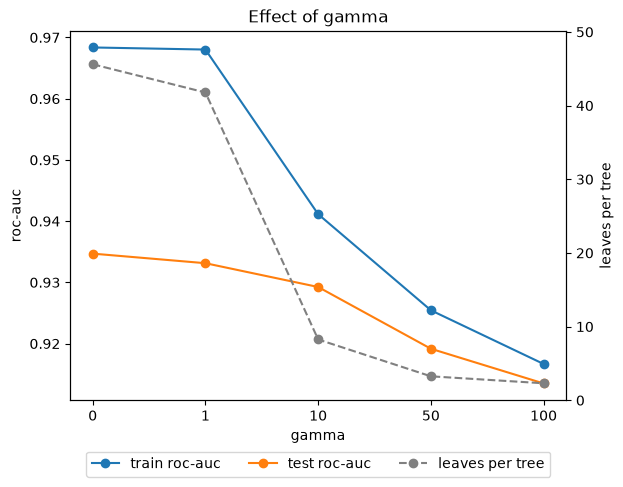

In [24]:
plot_sweep(gamma_results, "gamma", "leaves per tree")

As `gamma` grows, the performance goes slightly down, and the test roc-auc falls from 0.9347 at a `gamma` of 0 to 0.9135 at 100. Already at a `gamma` of 10, the trees shrink from about 46 to 8 leaves, and at 100 they keep only 2 or 3. The train and the test roc-auc fall together, so with only 36 trees of depth 6 the model was not overfitting much, and `gamma` removes splits that the model needed.

In [25]:
lambda_results = sweep("lambda", [0, 1, 10, 50, 100], "mean abs leaf weight", mean_abs_weight)

lambda_results.round(4)

,train roc-auc,test roc-auc,mean abs leaf weight
0,0.9706,0.9317,0.2794
1,0.9684,0.9347,0.1919
10,0.9623,0.9349,0.0868
50,0.9530,0.9344,0.0424
100,0.9486,0.9330,0.0309


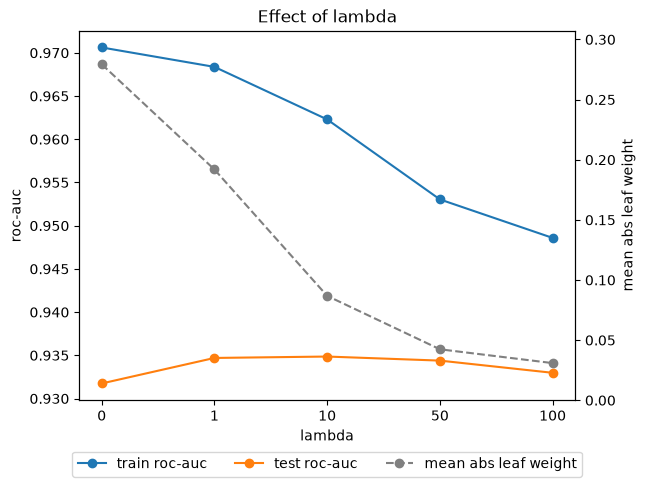

In [26]:
plot_sweep(lambda_results, "lambda", "mean abs leaf weight")

As `lambda` grows, the mean absolute leaf weight shrinks from about 0.28 to 0.03, so each tree moves the predictions less. The train roc-auc goes down steadily, while the test roc-auc stays almost the same, so with the same number of trees `lambda` reduces the gap between train and test at no cost in the test set.

## Callbacks and model IO

### Callbacks

A callback is an object that XGBoost calls at fixed points of the training, such as after every round. Early stopping and the printed evaluation log are built-in callbacks too: `xgb.train` adds `EarlyStopping` when we set `early_stopping_rounds`, and `EvaluationMonitor` when `verbose_eval` is on, which it is by default.

Here, we write one that prints the test roc-auc every 50 rounds and combine it with two more built-in callbacks: `LearningRateScheduler`, which sets the learning rate of each round from a function, and `TrainingCheckPoint`, which saves the model every 50 rounds.

The training uses the same early stopping as before, so it stops by itself, and we cut the booster to its best round, as before.

In [27]:
class PrintEvery(xgb.callback.TrainingCallback):
    def __init__(self, period):
        self.period = period

    def after_iteration(self, model, epoch, evals_log):
        if epoch % self.period == 0:
            print(f"round {epoch}: test roc-auc {evals_log['test']['auc'][-1]:.4f}")
        # returning True would stop the training
        return False

In [28]:
def decay(epoch):
    return 0.3 * 0.99 ** epoch


# TrainingCheckPoint does not create the folder, and we remove the files of an earlier run
checkpoints = pathlib.Path("checkpoints") / "classification"
checkpoints.mkdir(parents=True, exist_ok=True)
for path in checkpoints.glob("*.ubj"):
    path.unlink()

In [29]:
scheduled_result = {}

scheduled = xgb.train(
    params,
    dtrain,
    num_boost_round=2000,
    evals=[(dtrain, "train"), (dtest, "test")],
    early_stopping_rounds=50,
    evals_result=scheduled_result,
    verbose_eval=False,
    callbacks=[
        PrintEvery(50),
        xgb.callback.LearningRateScheduler(decay),
        xgb.callback.TrainingCheckPoint(directory=checkpoints, name="checkpoint", interval=50),
    ],
)

round 0: test roc-auc 0.8667


round 50: test roc-auc 0.9339


round 100: test roc-auc 0.9340


In [30]:
print(f"best number of trees: {scheduled.best_iteration + 1}, trees in the booster: {scheduled.num_boosted_rounds()}")

# keep only the trees up to the best round, as for our booster
scheduled = scheduled[:scheduled.best_iteration + 1]

evaluate(scheduled, dtrain, y_train, dtest, y_test)

best number of trees: 79, trees in the booster: 129
train balanced accuracy: 0.8400, roc-auc: 0.9763
test balanced accuracy: 0.7273, roc-auc: 0.9344


With the learning rate shrinking, the later trees add less and less, so early stopping finds the best round later, at 79 trees against 36 before. The test roc-auc ends about the same, 0.9344 against 0.9347, so the schedule does not beat a constant learning rate here.

The number in the file name is the index of the round, which counts from 0, so `checkpoint_50.ubj` holds 51 trees.

In [31]:
# sort by round number, not alphabetically
[path.name for path in sorted(checkpoints.iterdir(), key=lambda path: int(path.stem.split("_")[1]))]

['checkpoint_50.ubj', 'checkpoint_100.ubj']

### Save and load the model

We save the model in XGBoost's binary UBJSON format, which later versions of the library can still read, and load it into a new booster.

In [32]:
booster.save_model("xgboost-classification.ubj")
loaded = xgb.Booster(model_file="xgboost-classification.ubj")

np.array_equal(booster.predict(dtest), loaded.predict(dtest))

True

### Continue the training

Say that the training with the callbacks had been interrupted shortly after round 50. Then its last checkpoint is `checkpoint_50.ubj`, and there is no need to start again: we load the checkpoint, pass it to `xgb_model`, and XGBoost adds new trees on top of the ones that it already has. We add 100 trees with a smaller learning rate.

In [33]:
loaded = xgb.Booster(model_file=checkpoints / "checkpoint_50.ubj")

loaded.num_boosted_rounds()

51

In [34]:
continued = xgb.train(
    {**params, "eta": 0.05},
    dtrain,
    num_boost_round=100,
    evals=[(dtest, "test")],
    verbose_eval=25,
    xgb_model=loaded,
)

print(f"trees before: {loaded.num_boosted_rounds()}, trees after: {continued.num_boosted_rounds()}")

[0]	test-auc:0.93390


[25]	test-auc:0.93391


[50]	test-auc:0.93391


[75]	test-auc:0.93378


[99]	test-auc:0.93366


trees before: 51, trees after: 151


In [35]:
evaluate(continued, dtrain, y_train, dtest, y_test)

train balanced accuracy: 0.8437, roc-auc: 0.9766
test balanced accuracy: 0.7288, roc-auc: 0.9337


Starting from the 51 trees of the checkpoint, the 100 new trees with a learning rate of 0.05 barely move the test roc-auc, which ends at 0.9337, close to the 0.9347 of our booster.

## Feature importance

We saw in the lecture on feature importance that XGBoost builds three summaries for every feature from its splits: weight, gain and cover. We plot each type separately, from the most to the least important feature.

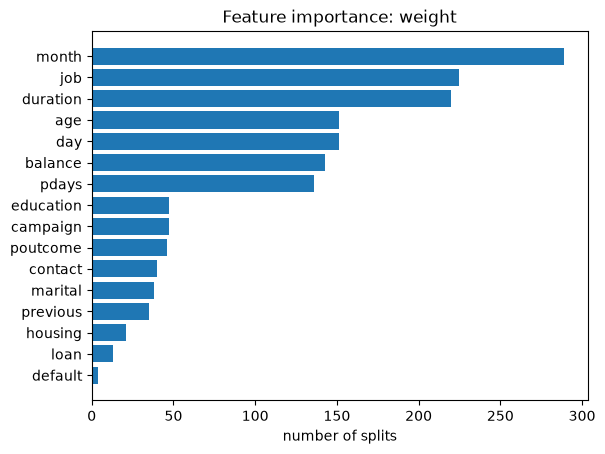

In [36]:
weight = pd.Series(booster.get_score(importance_type="weight")).sort_values(ascending=False)

# the most important feature on top
plt.barh(weight.index[::-1], weight.values[::-1])
plt.xlabel("number of splits")
plt.title("Feature importance: weight")
plt.show()

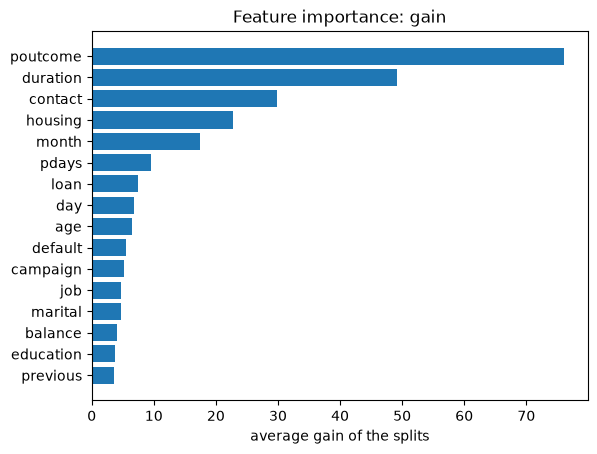

In [37]:
gain = pd.Series(booster.get_score(importance_type="gain")).sort_values(ascending=False)

# the most important feature on top
plt.barh(gain.index[::-1], gain.values[::-1])
plt.xlabel("average gain of the splits")
plt.title("Feature importance: gain")
plt.show()

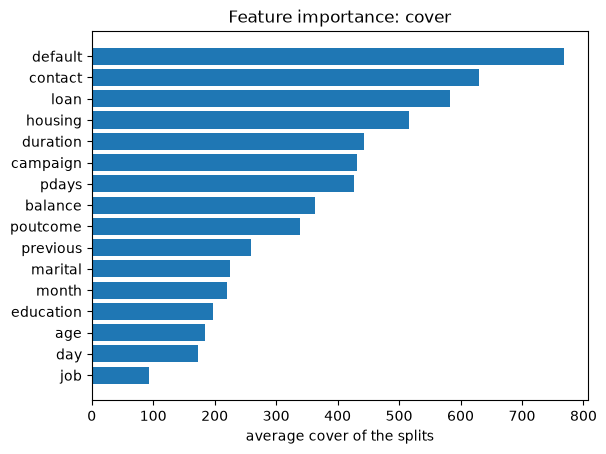

In [38]:
cover = pd.Series(booster.get_score(importance_type="cover")).sort_values(ascending=False)

# the most important feature on top
plt.barh(cover.index[::-1], cover.values[::-1])
plt.xlabel("average cover of the splits")
plt.title("Feature importance: cover")
plt.show()

The three charts disagree. By weight, `month`, `job` and `duration` come first, because variables with many values or categories offer many places to split. By gain, `poutcome`, `duration` and `contact` come first. By cover, `default`, `contact` and `loan` come first, because their few splits are reached by many clients whose predictions are uncertain, and those clients have large Hessians.